# Megane で分子を用意して、機械学習ポテンシャルで構造最適化する

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/megane-labs/megane/blob/main/examples/colab_ml_optimization.ipynb)

この notebook では次のことをします。

1. 分子 (初期設定はアスピリン、PubChem の化合物名でも指定可) を **Megane Builder** (`megane.Builder`) で開く (そのまま編集もできます)
2. 機械学習ポテンシャル **MACE** (ASE calculator) で構造最適化する
3. **最適化前を半透明**にして最適化後と重ね、構造変化を Megane で見る
4. (おまけ) 最適化の軌跡をアニメーションで再生する

Google Colab でもローカルの Jupyter / JupyterLab / VS Code でも動きます。GPU ランタイムがあれば自動で使いますが、小さな分子なら CPU でも数秒〜数十秒で終わります。

## 0. インストール

`megane` (ビューア + Builder)、`ase` (構造最適化)、`mace-torch` (機械学習ポテンシャル) を入れます。Colab には PyTorch が最初から入っています。

In [ ]:
%pip install -q megane ase mace-torch

In [ ]:
# In Colab, third-party widgets (anywidget) need the custom widget manager.
try:
    from google.colab import output

    output.enable_custom_widget_manager()
except ImportError:
    pass  # not on Colab

import warnings

import numpy as np
import torch
from ase.build import minimize_rotation_and_translation
from ase.io import read, write
from ase.optimize import BFGS

import megane

warnings.filterwarnings("ignore")  # torch / e3nn deprecation noise from MACE

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"megane {megane.__version__}, device = {device}")

## 1. Megane Builder で分子を用意する

下の 2 つのセルを実行すると、アスピリンの 3D 構造 ([PubChem](https://pubchem.ncbi.nlm.nih.gov/compound/2244) の立体配座。notebook に埋め込んであるのでネットワークは不要) を **Megane Builder** で開きます。別の分子で始めたいときは、`PUBCHEM_NAME` に PubChem の化合物名 (例: `"caffeine"`, `"ibuprofen"`) を入れてセルを再実行すると、PubChem から 3D 構造をダウンロードして開きます。

Builder の画面の見方:

- **上のバー**: ファイル名・組成・原子数・結合数 (例: `aspirin.sdf · C9H8O4 · 21 atoms · 21 bonds · …`)
- **左に縦に並んだアイコン**: 編集ツールです。アイコンにマウスを乗せると名前が出ます。上から **Select** (S)、**Move** (M)、**Add atom** (A)、**Bond** (B)、**Element** (E)、**Delete** (D)、**Place** (P) で、選んだツールの使い方は画面下の行に出ます。
- **右の Details パネル**: 選んでいるツールの設定 (Add atom / Element で使う元素など)
- **右下の History**: 編集の履歴 (ここから Undo もできます)

よく使う操作:

- **視点を変える**: 何もないところをドラッグで回転、スクロールでズーム。左上の **Reset View** で元に戻ります。
- **構造を崩す**: **Move** (十字の矢印のアイコン、キー `M`) を選んで原子をドラッグします。Shift を押しながらだと奥行き方向に動きます。
- **原子を足す・元素を変える・消す**: **Add atom** (A) で原子をクリックすると結合距離に新しい原子が付き、**Element** (E) で原子をクリックすると Details パネルで選んだ元素に変わり、**Delete** (D) で原子をクリックすると消えます。

**ポイント**: PubChem の 3D 構造はすでに力場で最適化されているので、そのままだと ML ポテンシャルで最適化しても変化は小さめです。変化をはっきり見たいときは、**Move** で原子をいくつか動かしておくか、次の節の `RATTLE` で乱数で崩してください。

In [ ]:
# @title 開始構造 (アスピリン) と PubChem から取ってくる関数 (読み飛ばして OK)
import time
import urllib.error
import urllib.parse
import urllib.request

ASPIRIN_MOL = """aspirin (PubChem CID 2244, 3D conformer)
  -OEChem-11042605393D

 21 21  0     0  0  0  0  0  0999 V2000
    1.2333    0.5540    0.7792 O   0  0  0  0  0  0  0  0  0  0  0  0
   -0.6952   -2.7148   -0.7502 O   0  0  0  0  0  0  0  0  0  0  0  0
    0.7958   -2.1843    0.8685 O   0  0  0  0  0  0  0  0  0  0  0  0
    1.7813    0.8105   -1.4821 O   0  0  0  0  0  0  0  0  0  0  0  0
   -0.0857    0.6088    0.4403 C   0  0  0  0  0  0  0  0  0  0  0  0
   -0.7927   -0.5515    0.1244 C   0  0  0  0  0  0  0  0  0  0  0  0
   -0.7288    1.8464    0.4133 C   0  0  0  0  0  0  0  0  0  0  0  0
   -2.1426   -0.4741   -0.2184 C   0  0  0  0  0  0  0  0  0  0  0  0
   -2.0787    1.9238    0.0706 C   0  0  0  0  0  0  0  0  0  0  0  0
   -2.7855    0.7636   -0.2453 C   0  0  0  0  0  0  0  0  0  0  0  0
   -0.1409   -1.8536    0.1477 C   0  0  0  0  0  0  0  0  0  0  0  0
    2.1094    0.6715   -0.3113 C   0  0  0  0  0  0  0  0  0  0  0  0
    3.5305    0.5996    0.1635 C   0  0  0  0  0  0  0  0  0  0  0  0
   -0.1851    2.7545    0.6593 H   0  0  0  0  0  0  0  0  0  0  0  0
   -2.7247   -1.3605   -0.4564 H   0  0  0  0  0  0  0  0  0  0  0  0
   -2.5797    2.8872    0.0506 H   0  0  0  0  0  0  0  0  0  0  0  0
   -3.8374    0.8238   -0.5090 H   0  0  0  0  0  0  0  0  0  0  0  0
    3.7290    1.4184    0.8593 H   0  0  0  0  0  0  0  0  0  0  0  0
    4.2045    0.6969   -0.6924 H   0  0  0  0  0  0  0  0  0  0  0  0
    3.7105   -0.3659    0.6426 H   0  0  0  0  0  0  0  0  0  0  0  0
   -0.2555   -3.5916   -0.7337 H   0  0  0  0  0  0  0  0  0  0  0  0
  1  5  1  0  0  0  0
  1 12  1  0  0  0  0
  2 11  1  0  0  0  0
  2 21  1  0  0  0  0
  3 11  2  0  0  0  0
  4 12  2  0  0  0  0
  5  6  1  0  0  0  0
  5  7  2  0  0  0  0
  6  8  2  0  0  0  0
  6 11  1  0  0  0  0
  7  9  1  0  0  0  0
  7 14  1  0  0  0  0
  8 10  1  0  0  0  0
  8 15  1  0  0  0  0
  9 10  2  0  0  0  0
  9 16  1  0  0  0  0
 10 17  1  0  0  0  0
 12 13  1  0  0  0  0
 13 18  1  0  0  0  0
 13 19  1  0  0  0  0
 13 20  1  0  0  0  0
M  END
"""


def fetch_pubchem_3d(name: str, path: str, tries: int = 4) -> bool:
    """Download PubChem's 3D conformer of *name* as SDF; retry while PubChem is busy."""
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{urllib.parse.quote(name)}/SDF?record_type=3d"
    for attempt in range(tries):
        try:
            urllib.request.urlretrieve(url, path)
            return True
        except OSError as exc:
            print(f"PubChem: {exc}")
            if isinstance(exc, urllib.error.HTTPError) and exc.code < 500:
                return False  # e.g. 404: no compound by that name
            time.sleep(2**attempt)
    return False

In [ ]:
# Leave empty to start from aspirin, or give a PubChem compound name ("caffeine", "ibuprofen", ...).
PUBCHEM_NAME = ""

start_file = "aspirin.mol"
if PUBCHEM_NAME:
    if fetch_pubchem_3d(PUBCHEM_NAME, PUBCHEM_NAME.replace(" ", "_") + ".sdf"):
        start_file = PUBCHEM_NAME.replace(" ", "_") + ".sdf"
    else:
        print(f"PubChem から {PUBCHEM_NAME!r} を取得できなかったので、アスピリンで始めます")
if start_file == "aspirin.mol":
    with open(start_file, "w") as f:
        f.write(ASPIRIN_MOL)

builder = megane.Builder(start_file, height="560px")
builder

## 2. Builder の構造を ASE の `Atoms` として取り出す

Builder は編集のたびに構造を Python 側に書き戻すので、`builder.to_ase()` で画面上の構造 (Builder で編集した結果) をそのまま取り出せます。

In [ ]:
# Random displacement (Å standard deviation) applied before optimizing, so the
# change is easy to see. Set to 0.0 to optimize the structure as is.
RATTLE = 0.15

if builder.n_atoms > 0:
    atoms_init = builder.to_ase()
    print(f"Builder から {builder.n_atoms} 原子 / {builder.n_bonds} 結合を読み込みました")
else:
    # The Builder has not sent its structure back (e.g. it was never shown in a browser).
    atoms_init = read(start_file)
    print(f"Builder の構造がまだ届いていないので、{start_file} をそのまま使います")

# A molecule in vacuum: no periodic boundary conditions.
if not atoms_init.cell.any():
    atoms_init.pbc = False

if RATTLE > 0:
    atoms_init.rattle(stdev=RATTLE, seed=0)

print(atoms_init.get_chemical_formula(), f"({len(atoms_init)} atoms)")

## 3. 機械学習ポテンシャルを用意する

[MACE](https://github.com/ACEsuit/mace) の学習済みモデルを ASE calculator として使います。初回はモデル (数十 MB) を自動でダウンロードします。

| `MODEL` | 中身 | 向いている系 | ライセンス |
| --- | --- | --- | --- |
| `"mace-off"` | MACE-OFF23 (small) | 有機分子 (H, C, N, O, F, P, S, Cl, Br, I) | ASL (学術・非商用) |
| `"mace-mp"` | MACE-MP-0 (small) | 周期表のほぼ全元素・無機材料 | MIT |

有機分子なら `"mace-off"`、金属や無機を含むなら `"mace-mp"` を選んでください。

In [ ]:
from mace.calculators import mace_mp, mace_off

MODEL = "mace-off"  # or "mace-mp"

if MODEL == "mace-off":
    calc = mace_off(model="small", device=device, default_dtype="float64")
else:
    calc = mace_mp(model="small", device=device, default_dtype="float64")

## 4. 構造最適化

BFGS で、全原子にかかる力が `FMAX` (eV/Å) 以下になるまで最適化します。各ステップの構造は `opt.traj` に保存されます (最後の節で再生します)。

In [ ]:
FMAX = 0.01  # eV/Å
MAX_STEPS = 500

# Energy of the starting structure.
atoms_init.calc = calc
e_init = atoms_init.get_potential_energy()

atoms_opt = atoms_init.copy()
atoms_opt.calc = calc
opt = BFGS(atoms_opt, trajectory="opt.traj", logfile="-")
converged = opt.run(fmax=FMAX, steps=MAX_STEPS)
e_opt = atoms_opt.get_potential_energy()

print()
print(f"収束: {converged} ({opt.get_number_of_steps()} steps)")
print(f"E(最適化前) = {e_init:.4f} eV")
print(f"E(最適化後) = {e_opt:.4f} eV")
print(f"ΔE          = {e_opt - e_init:.4f} eV")

## 5. 最適化前を半透明にして重ねて表示する

並進・回転で最適化後の構造を最適化前に重ね合わせて (Kabsch)、RMSD と大きく動いた原子を確認したあと、2 つの構造を 1 つのビューに重ねます。

Megane のパイプラインでは、`LoadStructure` を 2 つ同じ `Viewport` につなぐと、2 つのレイヤーとして重ねて描けます。最適化前の原子 (particle) と結合 (bond) をそれぞれ `Modify(opacity=0.3)` に通して半透明にしています。

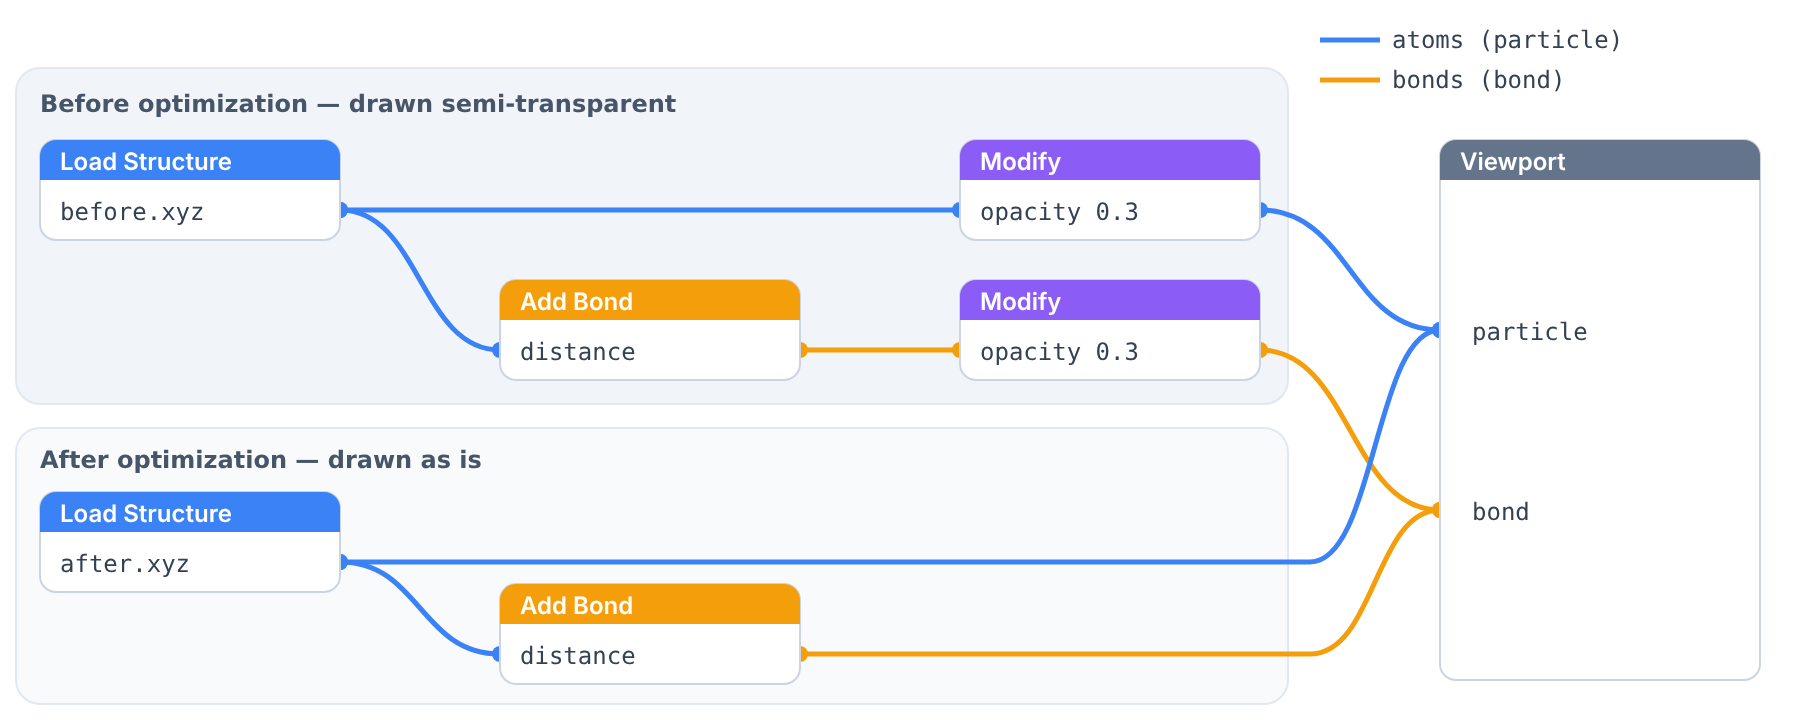

In [ ]:
# Superimpose the optimized structure onto the initial one (rotation + translation only).
minimize_rotation_and_translation(atoms_init, atoms_opt)

disp = np.linalg.norm(atoms_opt.positions - atoms_init.positions, axis=1)
rmsd = np.sqrt(np.mean(disp**2))
print(f"RMSD = {rmsd:.3f} Å, 最大変位 = {disp.max():.3f} Å")
print("大きく動いた原子:")
for i in np.argsort(disp)[::-1][:5]:
    print(f"  #{i:<3d} {atoms_init[i].symbol:<2s} {disp[i]:.3f} Å")

write("before.xyz", atoms_init)
write("after.xyz", atoms_opt)

In [ ]:
def compare_viewer(before: str, after: str, *, before_opacity: float = 0.3) -> megane.MolecularViewer:
    """Overlay two structures; *before* is drawn semi-transparent."""
    pipe = megane.Pipeline()
    view = pipe.add_node(megane.Viewport())

    # Before optimization: atoms and bonds both through Modify(opacity).
    s0 = pipe.add_node(megane.LoadStructure(before))
    b0 = pipe.add_node(megane.AddBonds(source="distance"))
    atoms_ghost = pipe.add_node(megane.Modify(opacity=before_opacity))
    bonds_ghost = pipe.add_node(megane.Modify(opacity=before_opacity))
    pipe.add_edge(s0.out.particle, atoms_ghost.inp.particle)
    pipe.add_edge(atoms_ghost.out.particle, view.inp.particle)
    pipe.add_edge(s0.out.particle, b0.inp.particle)
    # Modify accepts bond data on the same port and returns bonds.
    pipe.add_edge(b0.out.bond, bonds_ghost.inp.particle)
    pipe.add_edge(bonds_ghost.out.particle, view.inp.bond)

    # After optimization: drawn as is.
    s1 = pipe.add_node(megane.LoadStructure(after))
    b1 = pipe.add_node(megane.AddBonds(source="distance"))
    pipe.add_edge(s1.out.particle, view.inp.particle)
    pipe.add_edge(s1.out.particle, b1.inp.particle)
    pipe.add_edge(b1.out.bond, view.inp.bond)

    viewer = megane.MolecularViewer()
    viewer.set_pipeline(pipe)
    return viewer


compare_viewer("before.xyz", "after.xyz", before_opacity=0.3)

半透明のほうが **最適化前**、不透明のほうが **最適化後** です。ドラッグで回転、スクロールでズームできます。`before_opacity` を変えると透け具合を調整できます (0 で非表示、1 で不透明)。

最適化後の構造は `after.xyz` に保存されています。Builder に戻して続きを編集することもできます: `builder.load("after.xyz")`。

## 6. (おまけ) 最適化の軌跡を再生する

`opt.traj` (ASE trajectory) をそのまま Megane で開くと、最適化の各ステップをスライダーで再生できます。

In [ ]:
traj_viewer = megane.view_traj("opt.traj")
print(f"{traj_viewer.total_frames} frames")
traj_viewer